# DRIVE MOUNTING & ENVIRONMENT SETUP

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import optuna
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
import matplotlib.pyplot as plt
import numpy as np

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Verify project folder contents in Google Drive
drive_folder = "/content/drive/MyDrive/Plant_Disease_Project"
print("Files in project folder:")
for file in os.listdir(drive_folder):
    print(file)

zip_path = os.path.join(drive_folder, "PLANT DISEASE PROJECT .zip")
print("\nDataset ZIP exists:", os.path.exists(zip_path))

Files in project folder:
PLANT DISEASE PROJECT .zip
cloudflared
app.py
requirements.txt
README.md
tomato_svm_model.joblib

Dataset ZIP exists: True


# DATASET INSPECTION & EXTRACTION

In [ ]:
import zipfile
from tqdm import tqdm

extract_path = "/content/tomato_dataset"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    tomato_files = [
        f for f in z.namelist()
        if len(f.split("/")) >= 5
        and f.split("/")[2] in ["train", "valid"]
        and f.split("/")[3].startswith("Tomato___")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print("Total tomato images to extract:", len(tomato_files))

    for file in tqdm(tomato_files, desc="Extracting Dataset"):
        parts = file.split("/")
        split = parts[2]
        class_name = parts[3]
        filename = parts[-1]

        destination = os.path.join(extract_path, split, class_name, filename)
        os.makedirs(os.path.dirname(destination), exist_ok=True)

        with z.open(file) as source, open(destination, "wb") as target:
            target.write(source.read())

print("Extraction completed successfully!")

Total tomato images to extract: 45860


Extracting Dataset: 100%|██████████| 45860/45860 [00:28<00:00, 1588.84it/s]

Extraction completed successfully!


# DATA LOADING & NORMALIZATION

In [ ]:
TRAIN_DIR = os.path.join(extract_path, "train")
VALID_DIR = os.path.join(extract_path, "valid")

IMG_SIZE = (64, 64)  # Standardized size matching your pipeline
BATCH_SIZE = 32

# Load training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

# Load validation data
val_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(f"\nDetected {NUM_CLASSES} Target Plant Disease Classes:")
for idx, name in enumerate(class_names):
    print(f"  {idx}: {name}")

# Normalization layer (scales pixel values from [0, 255] to [0.0, 1.0])
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# Optimize performance with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

Found 18345 files belonging to 10 classes.
Found 4585 files belonging to 10 classes.

Detected 10 Target Plant Disease Classes:
  0: Tomato___Bacterial_spot
  1: Tomato___Early_blight
  2: Tomato___Late_blight
  3: Tomato___Leaf_Mold
  4: Tomato___Septoria_leaf_spot
  5: Tomato___Spider_mites Two-spotted_spider_mite
  6: Tomato___Target_Spot
  7: Tomato___Tomato_Yellow_Leaf_Curl_Virus
  8: Tomato___Tomato_mosaic_virus
  9: Tomato___healthy


# OPTUNA OBJECTIVE FUNCTION & MODEL BUILDER

In [ ]:
def objective(trial):
    # Hyperparameters to tune
    n_layers = trial.suggest_int("n_layers", 1, 3)             # Number of hidden layers
    hidden_units = trial.suggest_int("hidden_units", 64, 512)    # Neurons per dense layer
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.5) # Regularization dropout
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "SGD"])

    # Build model dynamically
    model = Sequential()
    model.add(Input(shape=(64, 64, 3)))
    model.add(Flatten())

    # Add dynamic hidden layers with dropout
    for i in range(n_layers):
        model.add(Dense(hidden_units, activation="relu", name=f"hidden_{i+1}"))
        model.add(Dropout(dropout_rate, name=f"dropout_{i+1}"))

    # Output layer for multi-class classification
    model.add(Dense(NUM_CLASSES, activation="softmax", name="output"))

    # Dynamic Optimizer selection
    if optimizer_name.lower() == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate=learning_rate)
    else:
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

    # Compile Model
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train Model (shortened epochs during trials for speed)
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        verbose=0
    )

    # Return best validation accuracy for the trial
    return max(history.history["val_accuracy"])

# EXECUTE OPTUNA STUDY

In [ ]:
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)  # Adjust n_trials based on available time/GPU

print("\n" + "=" * 40)
print("BEST TRIAL RESULTS:")
print("=" * 40)
trial = study.best_trial
print(f"  Best Validation Accuracy: {trial.value:.4f}")
print("  Best Hyperparameters:")
for key, value in trial.params.items():
    print(f"    {key}: {value}")

[I 2026-11-18 11:03:47,811] A new study created in memory with name: no-name-7e5adedd-92af-45c6-9046-30874fecf494
[I 2026-11-18 11:10:15,578] Trial 0 finished with value: 0.25779715180397034 and parameters: {'n_layers': 3, 'hidden_units': 175, 'dropout_rate': 0.32669835581865325, 'learning_rate': 0.0003339441062987608, 'optimizer': 'Adam'}. Best is trial 0 with value: 0.25779715180397034.
[I 2026-11-18 11:17:12,821] Trial 1 finished with value: 0.3365321755409241 and parameters: {'n_layers': 3, 'hidden_units': 172, 'dropout_rate': 0.16966748833281026, 'learning_rate': 0.0003524526889010668, 'optimizer': 'Adam'}. Best is trial 1 with value: 0.3365321755409241.
[I 2026-11-18 11:22:18,287] Trial 2 finished with value: 0.6261723041534424 and parameters: {'n_layers': 2, 'hidden_units': 249, 'dropout_rate': 0.3446039093998725, 'learning_rate': 0.0060525679761273534, 'optimizer': 'SGD'}. Best is trial 2 with value: 0.6261723041534424.
[I 2026-11-18 11:27:43,766] Trial 3 finished with value: 0


BEST TRIAL RESULTS:
  Best Validation Accuracy: 0.6816
  Best Hyperparameters:
    n_layers: 3
    hidden_units: 209
    dropout_rate: 0.12077792877464133
    learning_rate: 0.009878032822142046
    optimizer: SGD


# TRAIN FINAL MODEL WITH OPTIMIZED PARAMS

In [10]:
best_params = study.best_trial.params

# Extract best hyperparameters
best_n_layers = best_params["n_layers"]
best_hidden_units = best_params["hidden_units"]
best_dropout_rate = best_params["dropout_rate"]
best_lr = best_params["learning_rate"]
best_opt = best_params["optimizer"]

# Construct final model
final_model = Sequential()
final_model.add(Input(shape=(64, 64, 3)))
final_model.add(Flatten())

for i in range(best_n_layers):
    final_model.add(Dense(best_hidden_units, activation="relu"))
    final_model.add(Dropout(best_dropout_rate))

final_model.add(Dense(NUM_CLASSES, activation="softmax"))

optimizer_instance = keras.optimizers.Adam(learning_rate=best_lr) if best_opt.lower() == "adam" else keras.optimizers.SGD(learning_rate=best_lr)

final_model.compile(
    optimizer=optimizer_instance,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Fit final model with more epochs
history = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    verbose=1
)

Epoch 1/15
574/574 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.2902 - loss: 1.9919 - val_accuracy: 0.3738 - val_loss: 1.8158
Epoch 2/15
574/574 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.4446 - loss: 1.6004 - val_accuracy: 0.4704 - val_loss: 1.6107
Epoch 3/15
574/574 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.5123 - loss: 1.4165 - val_accuracy: 0.3832 - val_loss: 1.8881
Epoch 4/15
574/574 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.5473 - loss: 1.3141 - val_accuracy: 0.5692 - val_loss: 1.2215
Epoch 5/15
574/574 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - accuracy: 0.5806 - loss: 1.2201 - val_accuracy: 0.6033 - val_loss: 1.1910
Epoch 6/15
574/574 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.6040 - loss: 1.1497 - val_accuracy: 0.6430 - val_loss: 1.0379
Epoch 7/15
574/574 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.6231 - loss: 1.0915 - val_accuracy: 0.5302 - val_loss: 1.3308
Epoch 8/15
574/574 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.6397 - loss: 1.0404 - 

# EVALUATE & VISUALIZE RESULTS

144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.6964 - loss: 0.8858

Final Optimized ANN Validation Accuracy: 69.64%


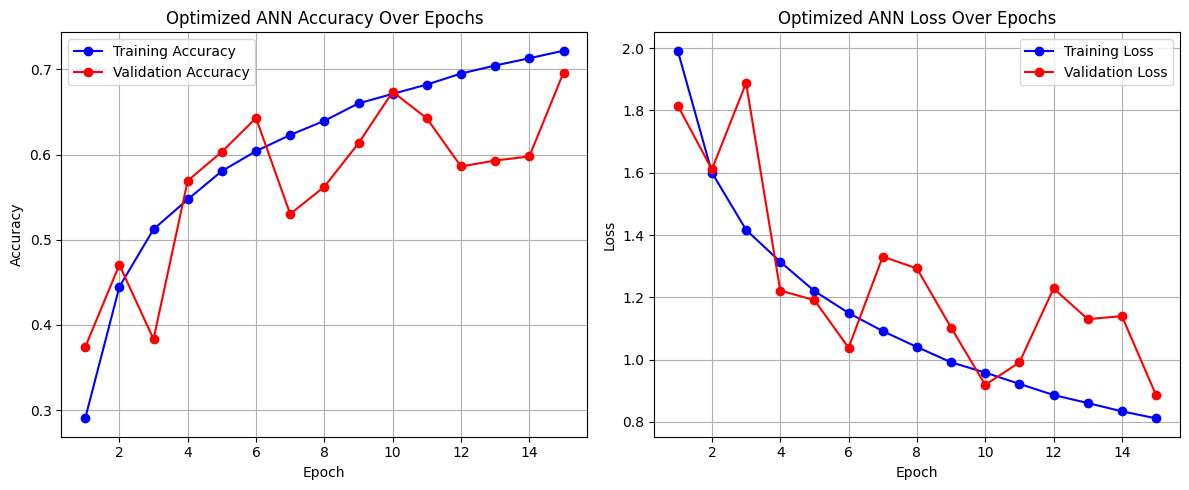

In [11]:
val_loss, val_accuracy = final_model.evaluate(val_ds)
print(f"\nFinal Optimized ANN Validation Accuracy: {val_accuracy * 100:.2f}%")

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'ro-', label='Validation Accuracy')
plt.title('Optimized ANN Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'bo-', label='Training Loss')
plt.plot(epochs_range, val_loss, 'ro-', label='Validation Loss')
plt.title('Optimized ANN Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# SAVE MODEL & SETUP DEPLOYMENT FOLDER

In [13]:
import os
import shutil

# 1. Save your trained ANN model to your Drive project folder
model_save_path = os.path.join(drive_folder, "tomato_ann_model.keras")
final_model.save(model_save_path)
print("ANN Model saved successfully at:", model_save_path)

# 2. Create local staging folder and copy files
destination = "/content/Plant_Disease_GitHub"
os.makedirs(destination, exist_ok=True)

# Note: We use 'tomato_ann_model.keras' instead of the old svm model
files_to_copy = ["app.py", "requirements.txt", "README.md", "tomato_ann_model.keras"]
for file in files_to_copy:
    src_file = os.path.join(drive_folder, file)
    if os.path.exists(src_file):
        shutil.copy2(src_file, os.path.join(destination, file))

print("Files staged successfully in:", destination)
print("Files present:", os.path.join(destination))

ANN Model saved successfully at: /content/drive/MyDrive/Plant_Disease_Project/tomato_ann_model.keras
Files staged successfully in: /content/Plant_Disease_GitHub
Files present: /content/Plant_Disease_GitHub
